# Fuga de clientes (churn): primer modelo

**Objetivo:** predecir qué clientes se van, comparando un modelo de referencia, una regresión logística y un random forest.

Los datos vienen del notebook anterior (`data/processed/telco_limpio.csv`).

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")
SEMILLA = 42

DATOS = Path("../data/processed/telco_limpio.csv")
FIGURAS = Path("../reports/figures")
MODELOS = Path("../models")
FIGURAS.mkdir(parents=True, exist_ok=True)
MODELOS.mkdir(parents=True, exist_ok=True)

## 1. Datos y partición entrenamiento / prueba

Separamos el 20 % de los clientes y no los tocamos hasta el final: son el examen del modelo. Con `stratify` se mantiene la misma proporción de fugas en ambos grupos.

In [2]:
df = pd.read_csv(DATOS)

y = df["churn"]
X = df.drop(columns=["customerID", "Churn", "churn"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEMILLA
)
print("Entrenamiento:", X_train.shape, f"| churn {y_train.mean():.1%}")
print("Prueba:       ", X_test.shape, f"| churn {y_test.mean():.1%}")

Entrenamiento: (5634, 19) | churn 26.5%
Prueba:        (1409, 19) | churn 26.5%


## 2. Preparación de variables

Los modelos solo entienden números:
- las variables numéricas se estandarizan (media 0, desviación 1),
- las categóricas se convierten en columnas 0/1 (*one-hot*).

Todo va dentro de un `Pipeline`, de modo que el aprendizaje de estas transformaciones ocurre solo con los datos de entrenamiento y no se filtra información del grupo de prueba.

In [3]:
numericas = ["tenure", "MonthlyCharges", "TotalCharges"]
categoricas = [c for c in X.columns if c not in numericas]

def preparar():
    return ColumnTransformer([
        ("num", StandardScaler(), numericas),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas),
    ])

print(len(numericas), "numéricas y", len(categoricas), "categóricas")

3 numéricas y 16 categóricas


## 3. Tres modelos

1. **Referencia (Dummy):** dice siempre "no se va". Es el piso: cualquier modelo útil debe superarlo.
2. **Regresión logística:** simple e interpretable.
3. **Random forest:** captura relaciones más complejas.

En los dos modelos reales usamos `class_weight="balanced"`: como solo ~27 % de los clientes se va, le damos más peso a esa clase para que el modelo no la ignore.

In [4]:
modelos = {
    "Referencia (Dummy)": DummyClassifier(strategy="most_frequent"),
    "Regresión logística": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEMILLA),
    "Random forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample",
        random_state=SEMILLA, n_jobs=-1,
    ),
}

pipelines = {n: Pipeline([("prep", preparar()), ("modelo", m)]) for n, m in modelos.items()}
for pipe in pipelines.values():
    pipe.fit(X_train, y_train)
print("Modelos entrenados:", list(pipelines))

Modelos entrenados: ['Referencia (Dummy)', 'Regresión logística', 'Random forest']


## 4. Resultados en el grupo de prueba

- **Accuracy:** porcentaje total de aciertos.
- **Precision:** de los clientes que el modelo marca como "se va", cuántos realmente se van.
- **Recall:** de los clientes que realmente se van, cuántos detecta el modelo.
- **F1:** equilibrio entre precision y recall.
- **ROC AUC:** capacidad de ordenar a los clientes por riesgo (0,5 = azar, 1 = perfecto).

In [5]:
filas = []
for nombre, pipe in pipelines.items():
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    filas.append({
        "modelo": nombre,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, proba),
    })

resultados = pd.DataFrame(filas).set_index("modelo").round(3)
resultados

,accuracy,precision,recall,f1,roc_auc
modelo,,,,,
Referencia (Dummy),0.735,0.000,0.000,0.000,0.500
Regresión logística,0.738,0.504,0.783,0.614,0.842
Random forest,0.776,0.560,0.741,0.638,0.842


Fíjate en la fila de referencia: su *accuracy* es alta, pero su *recall* es 0. No detecta a ningún cliente que se va. Por eso en un problema desbalanceado no basta con mirar la exactitud.

## 5. Validación cruzada

Un único corte entrenamiento/prueba puede dar suerte o mala suerte. Repetimos el entrenamiento en 5 particiones distintas del grupo de entrenamiento y miramos el ROC AUC de cada una.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
for nombre in ["Regresión logística", "Random forest"]:
    puntajes = cross_val_score(pipelines[nombre], X_train, y_train, cv=cv, scoring="roc_auc")
    print(f"{nombre}: ROC AUC = {puntajes.mean():.3f} ± {puntajes.std():.3f}")

Regresión logística: ROC AUC = 0.846 ± 0.012
Random forest: ROC AUC = 0.845 ± 0.009


## 6. Curvas ROC y matriz de confusión

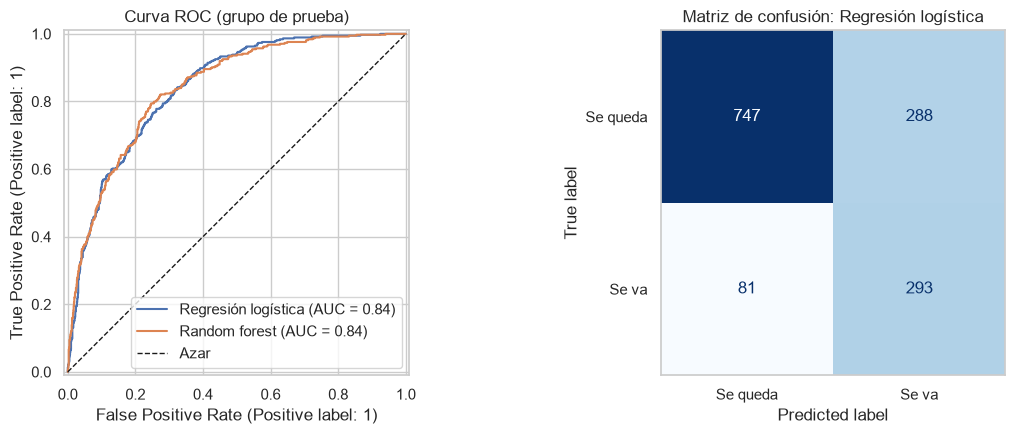

Mejor modelo por ROC AUC: Regresión logística


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for nombre in ["Regresión logística", "Random forest"]:
    RocCurveDisplay.from_estimator(pipelines[nombre], X_test, y_test, name=nombre, ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1, label="Azar")
axes[0].set_title("Curva ROC (grupo de prueba)")
axes[0].legend(loc="lower right")

mejor = resultados.drop(index="Referencia (Dummy)")["roc_auc"].idxmax()
ConfusionMatrixDisplay.from_estimator(
    pipelines[mejor], X_test, y_test, display_labels=["Se queda", "Se va"],
    cmap="Blues", colorbar=False, ax=axes[1],
)
axes[1].set_title(f"Matriz de confusión: {mejor}")
axes[1].grid(False)

plt.tight_layout()
plt.savefig(FIGURAS / "05_roc_y_confusion.png", dpi=150)
plt.show()
print("Mejor modelo por ROC AUC:", mejor)

## 7. ¿Qué variables pesan más?

En la regresión logística, cada coeficiente indica cuánto sube o baja el riesgo de fuga. Los de mayor valor absoluto son los que más influyen.

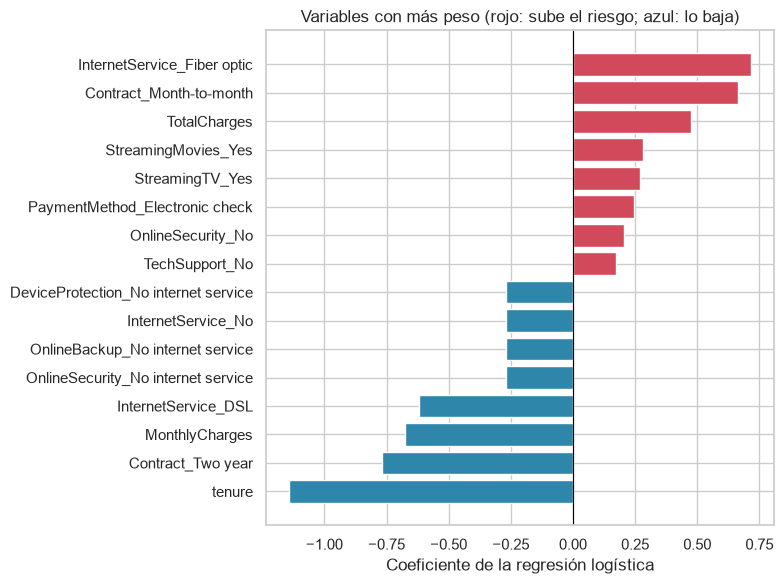

In [8]:
logit = pipelines["Regresión logística"]
nombres = logit.named_steps["prep"].get_feature_names_out()
coef = pd.Series(logit.named_steps["modelo"].coef_[0], index=nombres)
coef.index = coef.index.str.replace("num__", "", regex=False).str.replace("cat__", "", regex=False)

top = pd.concat([coef.sort_values().head(8), coef.sort_values().tail(8)])

fig, ax = plt.subplots(figsize=(8, 6))
colores = ["#d1495b" if v > 0 else "#2e86ab" for v in top.values]
ax.barh(top.index, top.values, color=colores)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Variables con más peso (rojo: sube el riesgo; azul: lo baja)")
ax.set_xlabel("Coeficiente de la regresión logística")
plt.tight_layout()
plt.savefig(FIGURAS / "06_coeficientes_logistica.png", dpi=150)
plt.show()

## 8. Conclusiones del paso 3

1. **¿Qué modelo rinde mejor?**  La regresión logística y el random forest empatan (ROC AUC 0,84), muy por encima de la referencia (0,50). Se elige la logística por ser más simple e interpretable.
2. **¿Cuántos detecta y a qué costo?** Detecta 293 de las 374 fugas del grupo de prueba (recall 78 %), a cambio de 288 falsas alarmas (precision 50 %).
3. **¿Qué variables pesan?** Suben el riesgo: fibra óptica, contrato mes a mes, sin soporte técnico ni seguridad en línea, y pago con cheque electrónico. Lo bajan: mayor antigüedad y contratos largos.

In [9]:
joblib.dump(pipelines[mejor], MODELOS / "modelo_churn.joblib")
print("Modelo guardado:", MODELOS / "modelo_churn.joblib")

Modelo guardado: ..\models\modelo_churn.joblib
